# PFE proposal C — MLOps: drift monitoring + champion/challenger retraining with rollback
Prequential simulation on a real non-stationary stream (Elec2 electricity market, OpenML id 151), in weekly batches.
Compares **static**, **periodic retraining** and **drift-triggered champion/challenger** (shadow trial, quality gates, automatic rollback).
CPU only, ~3 minutes.

In [1]:
# Setup (Colab or local). CPU is enough unless a cell says [GPU — Colab T4].
%pip install -q scikit-learn pandas numpy matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


## Package source (embedded from `code/src/`, identical to the tested files)

In [2]:
import os, sys
os.makedirs('src', exist_ok=True)
os.makedirs('src/driftops', exist_ok=True)
sys.path.insert(0, os.path.abspath('src'))

In [3]:
%%writefile src/driftops/__init__.py
"""Drift monitoring (PSI) + quality gates + champion/challenger retraining with rollback, on a labelled stream."""
from . import data, drift, gates, loop, registry  # noqa: F401


Writing src/driftops/__init__.py


In [4]:
%%writefile src/driftops/data.py
"""Streams for drift experiments.

Real: 'electricity' (Elec2, NSW market 1996–1998), OpenML data_id=151 — https://www.openml.org/d/151
Synthetic: logistic concept with an abrupt rotation + covariate shift (for tests).
"""
from __future__ import annotations

import numpy as np
import pandas as pd

FEATURES = ["day", "period", "nswprice", "nswdemand", "vicprice", "vicdemand", "transfer"]


def load_electricity(data_home: str | None = None) -> tuple[pd.DataFrame, np.ndarray]:
    from sklearn.datasets import fetch_openml
    d = fetch_openml(data_id=151, as_frame=True, data_home=data_home, parser="auto")
    df = d.frame
    X = df[FEATURES].astype(float).reset_index(drop=True)
    y = (df["class"].astype(str) == "UP").astype(int).to_numpy()
    return X, y  # rows are already in time order (half-hourly)


def batches(X: pd.DataFrame, y: np.ndarray, size: int = 336):
    """Yield consecutive (X_batch, y_batch). 336 half-hours = 1 week."""
    for s in range(0, len(X) - size + 1, size):
        yield X.iloc[s:s + size].reset_index(drop=True), y[s:s + size]


def make_synthetic_stream(n_batches: int = 40, size: int = 300, drift_at: int = 20, n_features: int = 5,
                          seed: int = 0) -> tuple[pd.DataFrame, np.ndarray]:
    rng = np.random.default_rng(seed)
    w_before = rng.normal(0, 1, n_features)
    w_after = -w_before + rng.normal(0, 0.3, n_features)  # concept flips
    Xs, ys = [], []
    for b in range(n_batches):
        shift = 1.0 if b >= drift_at else 0.0             # covariate shift on feature 0
        X = rng.normal(0, 1, (size, n_features))
        X[:, 0] += shift
        w = w_after if b >= drift_at else w_before
        p = 1 / (1 + np.exp(-(X @ w)))
        Xs.append(X)
        ys.append((rng.random(size) < p).astype(int))
    X = pd.DataFrame(np.vstack(Xs), columns=[f"x{i}" for i in range(n_features)])
    return X, np.concatenate(ys)


Writing src/driftops/data.py


In [5]:
%%writefile src/driftops/drift.py
"""Population Stability Index per feature (bins = reference quantiles)."""
from __future__ import annotations

import numpy as np
import pandas as pd


def psi(ref: np.ndarray, cur: np.ndarray, bins: int = 10, eps: float = 1e-4) -> float:
    ref, cur = np.asarray(ref, float), np.asarray(cur, float)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:  # (near-)constant reference: compare share of values equal to the reference value
        same_ref, same_cur = np.mean(ref == ref[0]), np.mean(cur == ref[0])
        p, q = np.array([same_ref, 1 - same_ref]) + eps, np.array([same_cur, 1 - same_cur]) + eps
        return float(np.sum((q - p) * np.log(q / p)))
    edges[0], edges[-1] = -np.inf, np.inf
    p = np.histogram(ref, edges)[0] / len(ref) + eps
    q = np.histogram(cur, edges)[0] / len(cur) + eps
    return float(np.sum((q - p) * np.log(q / p)))


def feature_psi(ref: pd.DataFrame, cur: pd.DataFrame, bins: int = 10) -> dict[str, float]:
    return {c: psi(ref[c].to_numpy(), cur[c].to_numpy(), bins) for c in ref.columns}


def drift_flag(psis: dict[str, float], threshold: float = 0.2, min_features: int = 1) -> bool:
    """Rule of thumb: PSI < 0.1 stable, 0.1–0.2 moderate, > 0.2 significant shift."""
    return sum(v > threshold for v in psis.values()) >= min_features


Writing src/driftops/drift.py


In [6]:
%%writefile src/driftops/gates.py
"""Offline quality gates a candidate must pass before it may challenge the champion."""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
from sklearn.metrics import roc_auc_score


def safe_auc(y, p) -> float:
    return float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else float("nan")


def ece(y, p, bins: int = 10) -> float:
    """Expected calibration error with equal-width bins."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.minimum((p * bins).astype(int), bins - 1)
    total = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            total += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(total)


@dataclass
class QualityGates:
    min_auc: float = 0.6
    max_ece: float = 0.15
    max_auc_drop_vs_champion: float = 0.02
    min_rows: int = 200

    def check(self, y, p, champion_auc: float | None = None) -> tuple[bool, list[str]]:
        reasons = []
        if len(y) < self.min_rows:
            reasons.append(f"too few rows ({len(y)} < {self.min_rows})")
        if not np.isfinite(p).all():
            reasons.append("non-finite predictions")
        auc = safe_auc(y, p)
        if not (auc >= self.min_auc):
            reasons.append(f"AUC {auc:.3f} < {self.min_auc}")
        e = ece(y, p)
        if e > self.max_ece:
            reasons.append(f"ECE {e:.3f} > {self.max_ece}")
        if champion_auc is not None and np.isfinite(champion_auc) and auc < champion_auc - self.max_auc_drop_vs_champion:
            reasons.append(f"AUC {auc:.3f} worse than champion {champion_auc:.3f}")
        return (not reasons), reasons


Writing src/driftops/gates.py


In [7]:
%%writefile src/driftops/loop.py
"""Prequential simulation of three maintenance strategies on a labelled stream:

- static:          train once, never retrain
- periodic:        retrain every `period` batches, promote if gates pass
- champion_challenger: retrain when drift (PSI) or a performance drop is detected; the challenger runs in
                   shadow for `shadow` batches and is promoted only if it beats the champion; automatic
                   rollback if the new champion underperforms right after promotion.

Each batch: (1) score with the current champion, (2) labels arrive, (3) log metrics, (4) maybe act.
The PSI reference is refreshed only on promotion (from data the promoted model was trained on), so a
slowly poisoned stream cannot silently move the reference.
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier

from .drift import drift_flag, feature_psi
from .gates import QualityGates, safe_auc
from .registry import ModelRegistry


def default_model(seed: int = 0):
    return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, random_state=seed)


@dataclass
class LoopConfig:
    strategy: str = "champion_challenger"   # static | periodic | champion_challenger
    window: int = 8                          # batches used to (re)train
    period: int = 4                          # periodic strategy
    shadow: int = 2                          # batches a challenger runs in shadow
    psi_threshold: float = 0.2
    perf_drop: float = 0.05                  # trigger if rolling AUC < reference AUC - perf_drop
    promote_margin: float = 0.0
    rollback_delta: float = 0.05
    cooldown: int = 2                        # batches between triggers
    seed: int = 0


def run_stream(batch_list: list[tuple[pd.DataFrame, np.ndarray]], cfg: LoopConfig, registry_dir: str,
               model_factory=default_model, gates: QualityGates | None = None) -> pd.DataFrame:
    gates = gates or QualityGates()
    reg = ModelRegistry(registry_dir)
    W = cfg.window
    hist_X = [b[0] for b in batch_list[:W]]
    hist_y = [b[1] for b in batch_list[:W]]

    def fit_on(Xs, ys):
        return model_factory(cfg.seed).fit(pd.concat(Xs, ignore_index=True), np.concatenate(ys))

    champ = fit_on(hist_X, hist_y)
    v = reg.register(champ, {"trained_on_batches": [0, W - 1]})
    reg.promote(v, "initial")
    reference = pd.concat(hist_X, ignore_index=True)
    ref_auc = None
    challenger, challenger_v, shadow_scores, challenger_ref = None, None, [], None
    prev_state = None  # (reference, ref_auc) before the last promotion, restored on rollback
    last_trigger, prev_champ_auc_on_shadow, just_promoted = -10, None, False
    logs = []

    for t in range(W, len(batch_list)):
        X, y = batch_list[t]
        p = champ.predict_proba(X)[:, 1]
        auc = safe_auc(y, p)
        acc = float(((p >= 0.5).astype(int) == y).mean())
        psis = feature_psi(reference, X)
        drift = drift_flag(psis, cfg.psi_threshold)
        row = {"batch": t, "auc": auc, "acc": acc, "psi_max": max(psis.values()), "psi_top": max(psis, key=psis.get), "drift": drift,
               "champion": reg.champion, "retrained": False, "promoted": False, "rolled_back": False, "gate_fail": ""}
        ref_auc = auc if ref_auc is None else ref_auc

        # post-promotion safety net
        if just_promoted and prev_champ_auc_on_shadow is not None and auc < prev_champ_auc_on_shadow - cfg.rollback_delta:
            back = reg.rollback(f"auc {auc:.3f} after promotion")
            if back is not None:
                champ = reg.load(back)
                reference, ref_auc = prev_state
                row["rolled_back"] = True
        just_promoted = False

        # shadow evaluation of a pending challenger
        if challenger is not None:
            shadow_scores.append((auc, safe_auc(y, challenger.predict_proba(X)[:, 1])))
            if len(shadow_scores) >= cfg.shadow:
                ch_mean = np.nanmean([s[1] for s in shadow_scores])
                cp_mean = np.nanmean([s[0] for s in shadow_scores])
                if ch_mean >= cp_mean + cfg.promote_margin:
                    reg.promote(challenger_v, f"shadow auc {ch_mean:.3f} vs {cp_mean:.3f}")
                    prev_state = (reference, ref_auc)
                    champ, row["promoted"], just_promoted = challenger, True, True
                    prev_champ_auc_on_shadow, ref_auc = cp_mean, ch_mean
                    reference = challenger_ref  # data the promoted model was trained on
                challenger, challenger_v, shadow_scores, challenger_ref = None, None, [], None

        hist_X.append(X)
        hist_y.append(y)

        # decide whether to (re)train
        trigger = False
        if cfg.strategy == "periodic":
            trigger = (t - W + 1) % cfg.period == 0
        elif cfg.strategy == "champion_challenger" and challenger is None and t - last_trigger >= cfg.cooldown:
            recent = [r["auc"] for r in logs[-1:]] + [auc]
            perf_bad = np.nanmean(recent) < ref_auc - cfg.perf_drop
            trigger = drift or perf_bad
        if trigger:
            last_trigger = t
            cand = fit_on(hist_X[-W - 1:-1], hist_y[-W - 1:-1])  # hold out the newest batch for the gates
            pc = cand.predict_proba(X)[:, 1]
            ok, reasons = gates.check(y, pc, champion_auc=None if cfg.strategy != "periodic" else auc)
            row["retrained"] = True
            if not ok:
                row["gate_fail"] = "; ".join(reasons)
            else:
                cand = fit_on(hist_X[-W:], hist_y[-W:])  # refit including newest batch
                cv = reg.register(cand, {"gate_auc": safe_auc(y, pc), "trained_upto": t})
                if cfg.strategy == "periodic":
                    reg.promote(cv, "periodic")
                    champ, row["promoted"] = cand, True
                    reference = pd.concat(hist_X[-W:], ignore_index=True)
                else:
                    challenger, challenger_v, shadow_scores = cand, cv, []
                    challenger_ref = pd.concat(hist_X[-W:], ignore_index=True)
        logs.append(row)
    return pd.DataFrame(logs)


def summarize(log: pd.DataFrame) -> dict:
    return {"mean_auc": float(log["auc"].mean()), "mean_acc": float(log["acc"].mean()),
            "retrains": int(log["retrained"].sum()), "promotions": int(log["promoted"].sum()),
            "rollbacks": int(log["rolled_back"].sum()), "drift_batches": int(log["drift"].sum())}


Writing src/driftops/loop.py


In [8]:
%%writefile src/driftops/registry.py
"""Minimal file-based model registry with champion promotion and rollback (swap for MLflow in the PFE)."""
from __future__ import annotations

import json
import time
from pathlib import Path

import joblib


class ModelRegistry:
    def __init__(self, root: str | Path):
        self.root = Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.meta_path = self.root / "registry.json"
        self.meta = json.loads(self.meta_path.read_text()) if self.meta_path.exists() else {"versions": [], "champion": None, "history": []}

    def _save(self):
        self.meta_path.write_text(json.dumps(self.meta, indent=2))

    def register(self, model, metrics: dict, tags: dict | None = None) -> int:
        v = len(self.meta["versions"]) + 1
        joblib.dump(model, self.root / f"model_v{v}.joblib")
        self.meta["versions"].append({"version": v, "metrics": metrics, "tags": tags or {}, "created": time.time()})
        self._save()
        return v

    def load(self, version: int):
        return joblib.load(self.root / f"model_v{version}.joblib")

    @property
    def champion(self) -> int | None:
        return self.meta["champion"]

    def promote(self, version: int, reason: str = "") -> None:
        self.meta["history"].append({"from": self.meta["champion"], "to": version, "reason": reason, "t": time.time()})
        self.meta["champion"] = version
        self._save()

    def rollback(self, reason: str = "") -> int | None:
        """Restore the champion that preceded the current one."""
        for h in reversed(self.meta["history"]):
            if h["to"] == self.meta["champion"] and h["from"] is not None:
                self.promote(h["from"], reason=f"rollback: {reason}")
                return h["from"]
        return None


Writing src/driftops/registry.py


In [9]:
import tempfile, pandas as pd
from driftops import data
from driftops.loop import LoopConfig, run_stream, summarize
try:
    X, y = data.load_electricity(); SOURCE = 'Elec2 (OpenML 151)'; SIZE = 336
except Exception as e:
    print('OpenML unavailable, synthetic stream:', e)
    X, y = data.make_synthetic_stream(60, 300, drift_at=30); SOURCE = 'synthetic'; SIZE = 300
B = list(data.batches(X, y, SIZE)); print(SOURCE, len(B), 'batches')

Elec2 (OpenML 151) 134 batches


In [10]:
logs = {s: run_stream(B, LoopConfig(strategy=s, window=8, period=4), tempfile.mkdtemp())
        for s in ['static', 'periodic', 'champion_challenger']}
pd.DataFrame({s: summarize(l) for s, l in logs.items()}).T

,mean_auc,mean_acc,retrains,promotions,rollbacks,drift_batches
static,0.764280,0.678453,0.0,0.0,0.0,126.0
periodic,0.838785,0.747000,31.0,14.0,0.0,126.0
champion_challenger,0.845141,0.747638,63.0,20.0,5.0,126.0


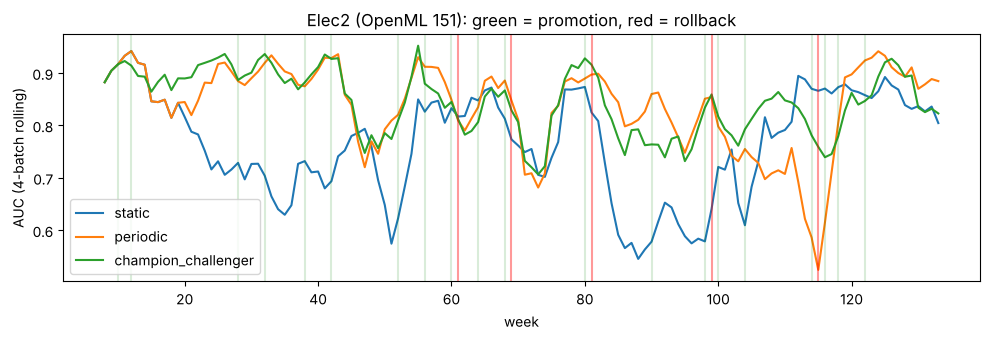

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 3.5))
for s, l in logs.items():
    plt.plot(l['batch'], l['auc'].rolling(4, min_periods=1).mean(), label=s)
cc = logs['champion_challenger']
for b in cc.loc[cc['promoted'], 'batch']: plt.axvline(b, color='green', alpha=.15)
for b in cc.loc[cc['rolled_back'], 'batch']: plt.axvline(b, color='red', alpha=.4)
plt.ylabel('AUC (4-batch rolling)'); plt.xlabel('week'); plt.legend(); plt.title(f'{SOURCE}: green = promotion, red = rollback'); plt.tight_layout(); plt.show()

### Alert fatigue: PSI on raw, autocorrelated features fires almost every week
One week of prices/demand is a narrow slice compared with an 8-week reference, so PSI is large even without a real concept change (median PSI ≈ 2.6 on this stream).
PFE question: which drift signal is *actionable*? Options: monitor the model-score distribution or residuals, use seasonal references, require multi-feature agreement.

In [12]:
cc[['psi_top']].value_counts().rename('batches where feature had max PSI').to_frame()

,batches where feature had max PSI
psi_top,
nswprice,47
nswdemand,34
vicprice,30
vicdemand,8
transfer,7


In [13]:
rows = []
for thr in [0.5, 2.0, 5.0]:
    l = run_stream(B, LoopConfig(strategy='champion_challenger', window=8, psi_threshold=thr), tempfile.mkdtemp())
    rows.append({'psi_threshold': thr, **summarize(l)})
pd.DataFrame(rows)

,psi_threshold,mean_auc,mean_acc,retrains,promotions,rollbacks,drift_batches
0,0.5,0.845141,0.747638,63,20,5,126
1,2.0,0.838396,0.754960,49,17,2,62
2,5.0,0.832851,0.735780,20,7,1,7


## Next steps for the PFE
1. Replace the stream with the host's model inputs + delayed labels; plug the registry into MLflow.
2. Add label-free performance estimation for when labels arrive late, plus per-segment monitoring.
3. Wire it as a scheduled pipeline (Airflow/Prefect or GitHub Actions) with a dashboard and alert routing.